In [2]:
import os
os.environ["OMP_NUM_THREADS"] = os.environ["MKL_NUM_THREADS"] = os.environ["OPENBLAS_NUM_THREADS"] = "8"
os.environ["XLA_PYTHON_CLIENT_ALLOCATOR"] = "platform"   # return JAX's GPU memory after each solve

import sys
sys.path.append("..")

# What helps and what hurts a cross-species alignment: one cost at a time, in 2D

The volume pipeline (`volume_align_demo.ipynb`) aligns human and mouse embryos with one fused GW solve. That solve mixes two sources of information: **space** (distances within each embryo) and **features** (the shared ortholog embedding). This notebook asks which of the two helps and which hurts. It does so on **real 2D sections**, which removes every stage-1 uncertainty (stacking, z gaps, field, volume sampling, the way back to the spots). The 3D version follows once these results are in.

Each section is aligned with one fixed partner of the other species: the section with the closest laterality L. The partner is chosen without labels and is the same for every run. Only the cost changes:

| run | within each section | between the sections | answers |
|---|---|---|---|
| `s-euc_f-euc` | Euclidean distances | features | the reference (the cost of the benchmark's `sec2sec_s-euc_f-euc_bal`, α = 0.5) |
| `s-euc_f-none` | Euclidean distances | none | how much space alone gets |
| `s-none_f-euc` | none | features | how much the features alone get (plain Wasserstein) |

For FGW the parameter α describes the weight of the GW term. 
Every run is solved balanced (τ = 1, as in `sec2sec_s-euc_f-euc_bal`) and unbalanced (τ = 0.95, so tissue without a counterpart can stay unmatched).

**Run names.** The runs follow `sides_space_features_marginals` (`docs/cross_species_alignment_results.md`, "Run names"). Every run here has the sides `sec2part` (the laterality partner section). In the main ablation the `run` column holds the space and features slots and the `tau` column the marginals (1: `bal`, 0.95: `ub`), so `s-euc_f-euc` at τ = 1 is `sec2part_s-euc_f-euc_bal`. In the follow-ups, `kind` is the sides slot (`sec2part`, `sec2emb`) and `run` the rest.

*The outputs below are from the run of 2026-10-23 and still show the old labels:* `fgw` = `s-euc_f-euc`, `gw` = `s-euc_f-none`, `w` = `s-none_f-euc`; in the follow-ups `fgw@α` = `s-eucα_f-euc_bal`, `w` = `s-none_f-euc_bal`, `w_semi@τ_b` = `s-none_f-euc_semiτ_b`, `w_nn` = `s-none_f-euc_nn`, `label_w` = `s-none_f-lab_bal`, `label_nn` = `s-none_f-lab_nn`, kind `partner section` = `sec2part`, `whole embryo` = `sec2emb`; `A_fgw` = `sec2sec_s-euc_f-euc_bal`, `PC_fgw` = `pts2pts_s-euc_f-euc_ub`.

*The label runs moved to [`label_alignment.ipynb`](label_alignment.ipynb)* (every pair of sections, any marginals): `s-eucα_f-lab` and `s-none_f-lab_bal` (`label_w` in the outputs below, which predate the move). Only the ceilings `s-none_f-lab_nn` stay here; a re-run refreshes the outputs.

**Two scores** for every query section, in both directions:
- **κ_bal**, the benchmark's metric. It is circular for the ceilings `s-none_f-lab_nn` of the follow-ups, which see the labels they are scored on.
- **gene r**, the mean Pearson r of the 500 held-out ortholog genes (never in the embedding) between each query spot and what P transports to it, minus the same with the target's spots shuffled. No run sees these genes, so this score is fair for all of them.

**What to keep in mind:**
- **Depth.** Partner sections can still be cut at different mediolateral positions, so organs go missing on one side. This hurts `s-euc_f-none` most.
- **Mirror images.** GW cannot tell a section from its mirror image. The `flip` column marks couplings whose best rigid map is a reflection when `s-euc_f-euc`'s is not, or the reverse.
- **No neighbourhoods for `s-none_f-euc`.** It matches by cell type, and the species batch effect stays in the features.
- **τ means different things for different costs.** The unbalanced runs weigh the same τ against costs on different scales, so they reject different amounts of mass (`matched`). The balanced runs are the clean comparison.

In [3]:
# ============================================================
# Run settings (papermill parameters)
# ============================================================
PAIR = "X4"                      # a cross pair of bench/configs/series.yaml (a = human, b = mouse)
SEED = 0
CONFIG = "bench.yaml"            # benchmark config (bench/configs)
PIPELINE = "sec2sec_s-euc_f-euc_bal"  # the 2D pipeline whose data and FGW settings are used
ROOT = None                      # benchmark root; None: $MGW_BENCH_DIR or <data dir>/bench
TAUS = (1.0, 0.95)               # marginal relaxation: 1 balanced, < 1 unbalanced
FGW_ALPHAS = (0.5, 0.9, 0.99)    # GW weights of the follow-up s-euc*_f-euc_bal runs
TAUS_B = (0.95, 0.9, 0.7, 0.5)   # target-side relaxation of the s-none_f-euc_semi* runs (query side balanced)
SHOW_SECTIONS = None             # human sections in figure 2; None: all

In [4]:
# Parameters
PAIR = "X4"
SEED = 0


In [5]:
import dataclasses
import time

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from ott.geometry import geometry
from ott.problems.linear import linear_problem
from ott.solvers.linear import sinkhorn
from scipy.spatial.distance import cdist

from mgw import crossspecies as cs
from mgw import stack3d as s3
from mgw.bench import config, metrics, prepare, series, solvers, store, volume
from mgw.bench.pipelines.common import Task
from mgw.bench.report.figures import OTHER, organ_palette

root = prepare.bench_root(ROOT)
cfg = config.load(CONFIG)
pair = series.load(cfg.series_path()).pairs[PAIR]
task = Task(cfg, PIPELINE, pair, SEED, root)
H, Mo = task.data["a"], task.data["b"]           # {name: Section}: human, mouse
print(f"pair {pair.id}: {pair.a.name} (human, {len(H)} sections) <-> {pair.b.name} (mouse, {len(Mo)} sections)")
print(f"root {root}\nFGW settings: {task.fgw}")

pair X4: CS18_E1 (human, 6 sections) <-> E12.5_E1 (mouse, 5 sections)
root /nas/lnt/ga79jin/MGW/data/bench
FGW settings: FGWParams(alpha=0.5, epsilon=0.005, inner_maxit=3000, outer_maxit=200, inner_tol=1e-07, outer_tol=1e-07)


## The partners

Every section is aligned with the section of the other embryo whose laterality L is closest (as the laterality partner in `bench/placement.py`). Direction `b_stack` has the human sections as queries, `a_stack` the mouse sections. A pair of sections that serves both directions is solved once; the mouse queries use the transpose of its coupling.

In [6]:
def partner(q, targets):
    ok = {n: t.L for n, t in targets.items() if np.isfinite(t.L)}
    return min(ok, key=lambda n: abs(ok[n] - q.L)) if np.isfinite(q.L) and ok else None


queries = [("b_stack", q, partner(H[q], Mo)) for q in H] + [("a_stack", q, partner(Mo[q], H)) for q in Mo]
queries = [(d, q, t) for d, q, t in queries if t is not None]
pairs = sorted({(q, t) if d == "b_stack" else (t, q) for d, q, t in queries})   # (human, mouse)
print(pd.DataFrame([dict(direction=d, query=q, L_query=(H if d == "b_stack" else Mo)[q].L, partner=t,
                         L_partner=(Mo if d == "b_stack" else H)[t].L) for d, q, t in queries]).round(3)
      .to_string(index=False))
print(f"\n{len(pairs)} pairs of sections to solve")

direction      query  L_query    partner  L_partner
  b_stack  CS18_E1S1    0.326 E12.5_E1S3      0.103
  b_stack  CS18_E1S2    0.560 E12.5_E1S5      0.667
  b_stack  CS18_E1S3    0.574 E12.5_E1S5      0.667
  b_stack  CS18_E1S4    0.574 E12.5_E1S5      0.667
  b_stack  CS18_E1S5    0.574 E12.5_E1S5      0.667
  b_stack  CS18_E1S6    0.667 E12.5_E1S5      0.667
  a_stack E12.5_E1S1    0.765  CS18_E1S6      0.667
  a_stack E12.5_E1S2    0.808  CS18_E1S6      0.667
  a_stack E12.5_E1S3    0.103  CS18_E1S1      0.326
  a_stack E12.5_E1S4    0.752  CS18_E1S6      0.667
  a_stack E12.5_E1S5    0.667  CS18_E1S6      0.667

9 pairs of sections to solve


## The costs and the solvers

- **Space:** max-normalized Euclidean distances within each section (centred, RMS radius 1), as in `pipelines/real2d.py`.
- **Features:** the benchmark's cross cost `task.cross_cost` (distances in the ortholog embedding over one scale per pair).
- **Labels:** the cost between two spots is 0 for the same organ, 1 for different organs, and 0.5 when either is `Other` or `Excluded` (no evidence either way), averaged over the organ compositions of the two spots. Only the ceilings `s-none_f-lab_nn` of the follow-ups use it.

`s-euc_f-none` and `s-euc_f-euc` use the benchmark's FGW solver (`solvers.fgw`), with α the weight of the GW term. `s-none_f-euc` uses entropic OT on the feature cost alone, with OTT's Sinkhorn at the same ε (`solvers.fgw` cannot do α = 0).

In [7]:
def label_cost(comp_a, comp_b):
    """Organ-label cross cost: 0 same organ, 1 different organs, 0.5 when a side is Other/Excluded."""
    Ka, Kb = metrics.row_normalize(comp_a)[:, metrics.SCORED], metrics.row_normalize(comp_b)[:, metrics.SCORED]
    return 1 - Ka @ Kb.T - 0.5 * (1 - np.outer(Ka.sum(1), Kb.sum(1)))


def ot_linear(M, tau, p, tau_b=None):
    """Entropic OT on the cross cost alone (unbalanced for tau < 1), uniform masses; tau_b: the target side's
    relaxation, if not tau (tau = 1, tau_b < 1: semi-relaxed, the query side balanced)."""
    t0 = time.perf_counter()
    geom = geometry.Geometry(cost_matrix=jnp.asarray(M, dtype=jnp.float32), epsilon=p.epsilon)
    out = sinkhorn.Sinkhorn(max_iterations=p.inner_maxit, threshold=p.inner_tol)(
        linear_problem.LinearProblem(geom, tau_a=tau, tau_b=tau if tau_b is None else tau_b))
    return np.asarray(out.matrix, dtype=np.float64), dict(converged=bool(out.converged),
                                                          seconds=time.perf_counter() - t0)


# run: the space and features slots of the name (sides: sec2part; marginals: the solve's tau, 1 bal, 0.95 ub)
# -> (cross cost, alpha = weight of the GW term; 0: Wasserstein only)
s_euc = lambda a: "s-euc" if a == 0.5 else f"s-euc{a:g}"   # the space slot: GW on Euclidean distances, weight a
RUNS = {"s-euc_f-euc": ("features", 0.5), "s-euc_f-none": (None, 1.0),
        "s-none_f-euc": ("features", 0.0)}


def solve(run, h, m, tau):
    cross, alpha = RUNS[run]
    M = task.cross_cost(h.emb, m.emb) if cross else None
    if alpha == 0:
        return ot_linear(M, tau, task.fgw)
    return solvers.fgw(None, None, M, dataclasses.replace(task.fgw, alpha=alpha), Ca=D[h.name], Cb=D[m.name],
                       tau_a=tau, tau_b=tau)


# the label cost on toy spots: heart, heart, brain, Other
toy = metrics.onehot(["Heart", "Heart", "Brain", "Other"])
assert np.allclose(label_cost(toy, toy), [[0, 0, 1, .5], [0, 0, 1, .5], [1, 1, 0, .5], [.5, .5, .5, .5]])
# Wasserstein: balanced marginals are uniform
Pt, _ = ot_linear(np.random.default_rng(0).random((30, 20)), 1.0, task.fgw)
assert np.allclose(Pt.sum(1), 1 / 30, atol=1e-4) and np.allclose(Pt.sum(0), 1 / 20, atol=1e-4)
print("toy checks passed; runs:", ", ".join(RUNS))

toy checks passed; runs: fgw, gw, label_fgw@0.5, label_fgw@0.9, label_fgw@0.99, w


## The features: what each PC weighs in the cross cost

The features are a joint PCA of the ortholog genes of both embryos (`orthologs.shared_embedding`). Every gene is z-scored within its section, both species are projected on the same PCs, and each PC keeps its scale (the scores U·S). So the more a PC varies, the more weight it has in the cross cost (a Euclidean distance). Every section is centred, so no PC carries an offset between the species. What can still differ between them is how much each PC varies, and whether it orders the organs the same way.

Per PC:
- **var_share:** its variance over the total variance of the embedding's genes (each z-scored to about 1); **cum_share** is the running sum, so its last row is how much of the expression the PCs keep.
- **cost_weight:** its variance over the sum over all PCs: its share of the mean squared distance in the cross cost.
- **log2_h_m:** log2 of its variance in the human over that in the mouse embryo. 0: both species vary along it equally; ±1: one varies twice as much. A large |value| marks an axis that one species barely has.
- **organ_R2_h, organ_R2_m:** the share of its variance that the organ explains, within each embryo.
- **organ_r:** the Pearson r between the organ means of the two embryos, over the organs both have. Near 1: the PC orders the organs the same way in both species, a shared axis the cross cost can use. Near 0 or below: it does not, and it adds distance between homologous spots.

The labels only serve to read the PCs here; no cost uses them.

In [8]:
FEAT_MIN_TILES = 20   # an organ enters organ_r with at least this many tiles in each embryo

E = {"human": np.vstack([s.emb for s in H.values()]), "mouse": np.vstack([s.emb for s in Mo.values()])}
codes = {"human": metrics.organ_codes(np.concatenate([s.label for s in H.values()])),
         "mouse": metrics.organ_codes(np.concatenate([s.label for s in Mo.values()]))}
n_genes = len(np.load(prepare.feature_file(root, pair.id, SEED, cfg.feature_hash()))["emb_genes"])
n_pc = E["human"].shape[1]


def organ_r2(X, c):
    """Per PC: the share of the variance over the scored tiles that the organ explains."""
    X, c = X[metrics.SCORED[c]], c[metrics.SCORED[c]]
    mu = X.mean(0)
    between = sum((c == o).sum() * (X[c == o].mean(0) - mu) ** 2 for o in np.unique(c))
    return between / ((X - mu) ** 2).sum(0)


def organ_means(X, c):
    """Organs x PCs: the mean of each PC over the tiles of a scored organ (NaN below FEAT_MIN_TILES tiles)."""
    M = np.full((len(metrics.ORGANS), X.shape[1]), np.nan)
    for o in np.unique(c[metrics.SCORED[c]]):
        if (c == o).sum() >= FEAT_MIN_TILES:
            M[o] = X[c == o].mean(0)
    return M


Mh, Mm = organ_means(E["human"], codes["human"]), organ_means(E["mouse"], codes["mouse"])
shared = np.isfinite(Mh[:, 0]) & np.isfinite(Mm[:, 0])
var = np.vstack(list(E.values())).var(0)
pcs = pd.DataFrame(dict(var_share=var / n_genes, cum_share=np.cumsum(var) / n_genes, cost_weight=var / var.sum(),
                        log2_h_m=np.log2(E["human"].var(0) / E["mouse"].var(0)),
                        organ_R2_h=organ_r2(E["human"], codes["human"]),
                        organ_R2_m=organ_r2(E["mouse"], codes["mouse"]),
                        organ_r=[np.corrcoef(Mh[shared, k], Mm[shared, k])[0, 1] for k in range(n_pc)]),
                   index=pd.RangeIndex(1, n_pc + 1, name="PC"))
print(f"{n_genes} genes in the embedding; its {n_pc} PCs keep {pcs.cum_share.iloc[-1]:.1%} of their variance")
print(f"organ_r over the {shared.sum()} organs with >= {FEAT_MIN_TILES} tiles in both embryos: "
      + ", ".join(np.asarray(metrics.ORGANS)[shared]))
print(f"cost weight on PCs with organ_r > 0.5: {pcs.cost_weight[pcs.organ_r > 0.5].sum():.0%}; "
      f"with |log2_h_m| > 1: {pcs.cost_weight[pcs.log2_h_m.abs() > 1].sum():.0%}\n")
print(pcs.round(3).to_string())

2430 genes in the embedding; its 30 PCs keep 18.7% of their variance
organ_r over the 13 organs with >= 20 tiles in both embryos: Brain, Craniofacial, Epidermis, Ganglion, Gut, Heart, Liver, Lung, Mesenchyme, Muscle, Skeleton, Spinal cord, Urogenital
cost weight on PCs with organ_r > 0.5: 85%; with |log2_h_m| > 1: 8%

    var_share  cum_share  cost_weight  log2_h_m  organ_R2_h  organ_R2_m  organ_r
PC                                                                              
1       0.051      0.051        0.271    -0.245       0.486       0.322    0.940
2       0.041      0.092        0.219    -0.874       0.678       0.563    0.965
3       0.027      0.118        0.144    -0.930       0.345       0.290    0.713
4       0.011      0.129        0.060    -1.299       0.202       0.202    0.630
5       0.007      0.137        0.039    -0.636       0.354       0.480    0.887
6       0.005      0.142        0.027    -0.608       0.544       0.324    0.467
7       0.005      0.146        

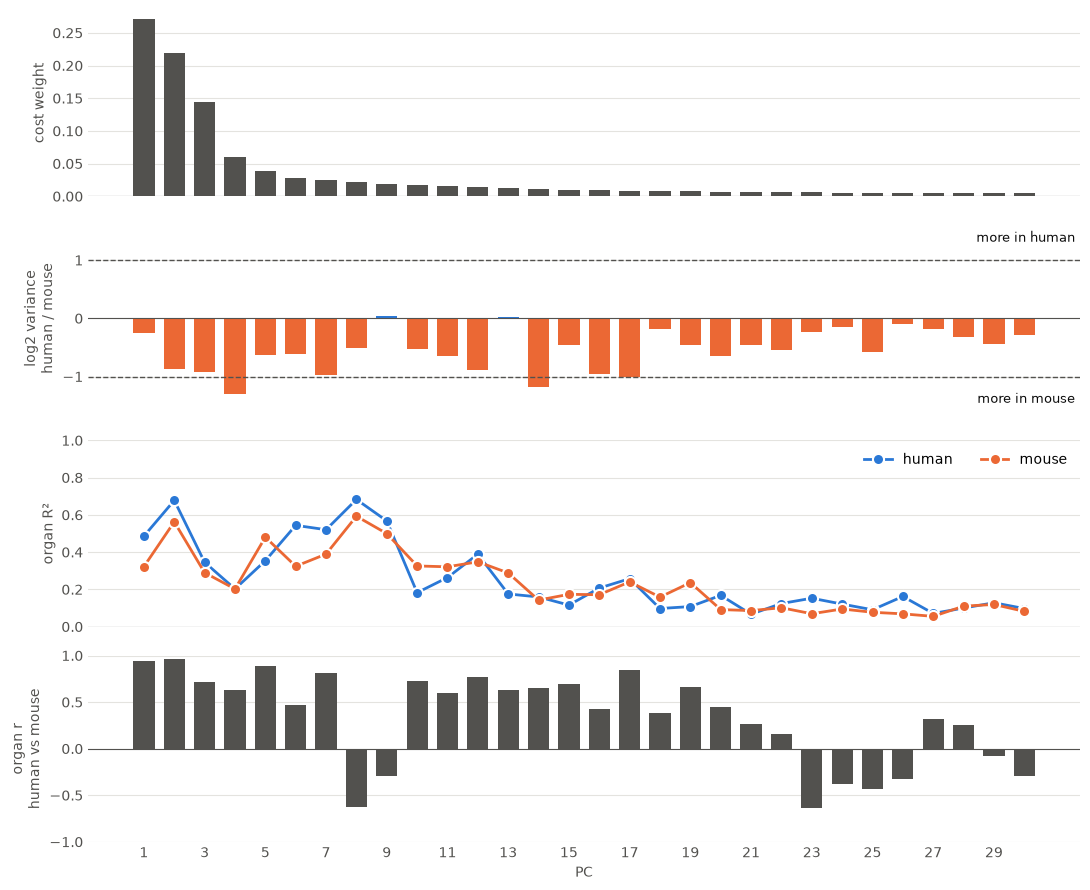

In [9]:
HUMAN, MOUSE = "#2a78d6", "#eb6834"               # categorical slots 1 and 2 (validated pair)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
x = pcs.index.to_numpy()
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
axes[0].bar(x, pcs.cost_weight, width=0.7, color=MUTED)
axes[0].set_ylabel("cost weight", color=MUTED)
axes[1].bar(x, pcs.log2_h_m, width=0.7, color=np.where(pcs.log2_h_m >= 0, HUMAN, MOUSE))
for y in (-1, 1):
    axes[1].axhline(y, color=MUTED, ls="--", lw=1)
axes[1].set_ylabel("log2 variance\nhuman / mouse", color=MUTED)
lim = max(1.6, 1.15 * pcs.log2_h_m.abs().max())
axes[1].set_ylim(-lim, lim)
axes[1].text(0.995, 0.97, "more in human", transform=axes[1].transAxes, ha="right", va="top", color=INK, fontsize=9)
axes[1].text(0.995, 0.03, "more in mouse", transform=axes[1].transAxes, ha="right", va="bottom", color=INK, fontsize=9)
for col, color, name in (("organ_R2_h", HUMAN, "human"), ("organ_R2_m", MOUSE, "mouse")):
    axes[2].plot(x, pcs[col], color=color, lw=2, marker="o", ms=8, mec="white", mew=1.5, label=name)
axes[2].set_ylim(0, 1)
axes[2].set_ylabel("organ R²", color=MUTED)
axes[2].legend(frameon=False, ncol=2, loc="upper right")
axes[3].bar(x, pcs.organ_r, width=0.7, color=MUTED)
axes[3].set_ylim(-1, 1)
axes[3].set_ylabel("organ r\nhuman vs mouse", color=MUTED)
axes[3].set_xlabel("PC", color=MUTED)
axes[3].set_xticks(x[::max(1, len(x) // 15)])
for ax in axes:
    ax.axhline(0, color=MUTED, lw=0.8)
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ax.spines.values():
        s.set_visible(False)
fig.tight_layout()
plt.show()

### Does the cost need all the PCs?

`s-none_f-euc` (features only, balanced, a few seconds per solve) on the first k PCs, with the cost scale recomputed for each k as in the benchmark (`solvers.cost_scale`). At k = all PCs it reproduces the balanced `s-none_f-euc` rows below. If κ_bal and gene r still rise between the last two k, more PCs might help (a new feature cache with a larger `features.pca_comp`). If they level off, more PCs will not help.

In [10]:
PC_KEEP = (5, 10, 20, n_pc)
f = cfg.raw["features"]
trunc = []
for k in sorted({k for k in PC_KEEP if k <= n_pc}):
    s = solvers.cost_scale(E["human"][:, :k], E["mouse"][:, :k], f["m_scale_quantile"], f["m_scale_max_entries"],
                           seed=SEED)
    assert k < n_pc or np.isclose(s, task.scale)
    for h, m in pairs:
        P, _ = ot_linear(cdist(H[h].emb[:, :k], Mo[m].emb[:, :k]) / s, 1.0, task.fgw)
        for d, qn, tn in queries:
            if (h, m) != ((qn, tn) if d == "b_stack" else (tn, qn)):
                continue
            q, t, Pq = (H[qn], Mo[tn], P) if d == "b_stack" else (Mo[qn], H[tn], P.T)
            r, r0 = cs.coexpression(Pq, q.Y, t.Y, seed=SEED)
            trunc.append(dict(n_pc=k, direction=d, query=qn,
                              kappa_bal=task.score(d, q, t.name, t.comp, Pq, keep=False)["kappa_bal"],
                              gene_r=np.nanmean(r) - np.nanmean(r0)))
trunc = pd.DataFrame(trunc)
print(trunc.groupby("n_pc")[["kappa_bal", "gene_r"]].mean().round(3).to_string())

      kappa_bal  gene_r
n_pc                   
5         0.190   0.345
10        0.266   0.359
20        0.293   0.360
30        0.295   0.361


## Quick follow-ups: the GW weight, the marginals, the ceiling and the whole target embryo

The ablation below (4 h) leaves four questions open. Each run here is a few seconds, except the FGW runs `s-euc*_f-euc_bal` (about 1 min per solve, 30 min in all), so this section runs on its own, before the long loop.

- **Does the GW term ever act?** `s-eucα_f-euc_bal` for α = 0.5 (the reference), 0.9 and 0.99, with both terms of the FGW objective logged: the GW energy and the feature cost of each coupling, next to those of `s-none_f-euc_bal` and of the independent coupling P = a bᵀ. If `s-euc_f-euc_bal` has almost the GW energy of `s-none_f-euc_bal`, the GW term barely moved the coupling at α = 0.5.
- **How much do the marginals cost?** Features only (`s-none_f-euc`) with the query side balanced and only the target side relaxed (semi-relaxed, `s-none_f-euc_semiτ_b`), down to `s-none_f-euc_nn`: each query spot spreads its mass over the target by exp(−M/ε), with no constraint on the target (τ_b → 0). Every query spot still counts the same for κ_bal, so only the target side needs relaxing.
- **What is the ceiling?** `s-none_f-lab_nn`: each query spot to the target spots of its own organ. It sees the labels it is scored on and bounds what any cost can reach on these partner sections. Balanced OT on the organ-label cost (`s-none_f-lab_bal`) is in `label_alignment.ipynb`.
- **Does the whole target embryo help?** The same `s-none_f-euc_*` runs with all spots of the other embryo as the target, not just the laterality partner. No stack, no geometry: if this comes close to `pts2pts_s-euc_f-euc_ub` (3D, stack points), most of the 3D gain is in having every depth to choose from, not in 3D geometry.

Extra columns: **target_used**, exp(entropy) of the target marginal over the number of target spots (1: every target spot gets the same mass); **dL**, the mass-weighted mean |L_target − L_query| (how far in depth the mass goes); **marg_err**, the largest relative error of the constrained marginals (both for balanced solves, the query's otherwise).

In [11]:
secs = {**H, **Mo}
D = {n: solvers.dist_norm(task.xy(secs[n])) for n in sorted({n for p in pairs for n in p})}
serves = {p: [(d, q, t) for d, q, t in queries if p == ((q, t) if d == "b_stack" else (t, q))] for p in pairs}


def softmax_nn(M, eps):
    """tau_b -> 0: each query spot spreads its mass over the target by exp(-M / eps); the target marginal is free."""
    L = -np.asarray(M, dtype=np.float32) / eps
    P = np.exp(L - L.max(1, keepdims=True))
    return P / P.sum(1, keepdims=True) / len(P)


def gw_terms(Ca, Cb, M, P):
    """(GW energy, feature cost) of P at mass 1: the two terms the FGW objective weighs by alpha and 1 - alpha."""
    P = jnp.asarray(P / P.sum(), dtype=jnp.float32)
    A, B = jnp.asarray(Ca, dtype=jnp.float32), jnp.asarray(Cb, dtype=jnp.float32)
    p, q = P.sum(1), P.sum(0)
    gw = p @ (A * A) @ p + q @ (B * B) @ q - 2 * ((A @ P) * (P @ B)).sum()
    return float(gw), float((jnp.asarray(M, dtype=jnp.float32) * P).sum())


def target_used(P):
    """exp(entropy) of the target marginal over the number of target spots: 1 when every spot gets the same mass."""
    b = P.sum(0) / P.sum()
    b = b[b > 0]
    return float(np.exp(-(b * np.log(b)).sum()) / P.shape[1])


def marg_err(P, balanced):
    """The largest relative error of the query marginal, and of the target's for a balanced solve."""
    e = np.abs(P.sum(1) * P.shape[0] - 1).max()
    return float(max(e, np.abs(P.sum(0) * P.shape[1] - 1).max()) if balanced else e)


def evaluate(d, q, tname, T, Yt, Lt, Pq):
    """kappa_bal, gene r, target_used and dL of a coupling Pq (rows: the query's spots)."""
    r, r0 = cs.coexpression(Pq, q.Y, Yt, seed=SEED)
    b, ok = np.asarray(Pq.sum(0), dtype=np.float64), np.isfinite(Lt)
    return dict(kappa_bal=task.score(d, q, tname, T, Pq, keep=False)["kappa_bal"],
                gene_r=np.nanmean(r) - np.nanmean(r0), target_used=target_used(Pq),
                dL=float((b[ok] * np.abs(Lt[ok] - q.L)).sum() / b[ok].sum()))


SEMI = [(f"s-none_f-euc_semi{tb:g}", tb) for tb in TAUS_B] + [("s-none_f-euc_nn", 0.0)]   # (run, tau_b)
FU_ORDER = ([f"{s_euc(a)}_f-euc_bal" for a in FGW_ALPHAS] + ["s-none_f-euc_bal"] + [r for r, _ in SEMI]
            + ["s-none_f-lab_nn"])

In [12]:
part_rows, terms, conv = [], [], []
eps = task.fgw.epsilon
for h, m in pairs:
    t0 = time.perf_counter()
    M, Ml = task.cross_cost(H[h].emb, Mo[m].emb), label_cost(H[h].comp, Mo[m].comp)
    # balanced solves: one coupling (human x mouse) serves both directions
    sym = {f"{s_euc(a)}_f-euc_bal": solvers.fgw(None, None, M, dataclasses.replace(task.fgw, alpha=a), Ca=D[h], Cb=D[m])
           for a in FGW_ALPHAS}
    sym["s-none_f-euc_bal"] = ot_linear(M, 1.0, task.fgw)
    for run, (P, info) in sym.items():
        conv.append(dict(run=run, human=h, mouse=m, converged=bool(info.get("converged")), n_outer=info.get("n_outer"),
                         inner_converged=info.get("inner_converged"), marg_err=marg_err(P, True),
                         seconds=info.get("seconds")))
    for run, P in [("independent", np.full(M.shape, 1 / M.size))] + [(r, sym[r][0]) for r in sym]:
        g, l = gw_terms(D[h], D[m], M, P)
        terms.append(dict(run=run, human=h, mouse=m, gw_energy=g, feature_cost=l))
    # semi-relaxed and nearest-neighbour solves: the query side stays balanced, so one per direction
    for d, qn, tn in serves[h, m]:
        q, t = (H[qn], Mo[tn]) if d == "b_stack" else (Mo[qn], H[tn])
        Mq, Mlq = (M, Ml) if d == "b_stack" else (M.T, Ml.T)
        runs = [(r, P if d == "b_stack" else P.T, True) for r, (P, _) in sym.items()]
        runs += [(r, softmax_nn(Mq, eps) if tb == 0 else ot_linear(Mq, 1.0, task.fgw, tau_b=tb)[0], False)
                 for r, tb in SEMI]
        runs.append(("s-none_f-lab_nn", softmax_nn(Mlq, eps), False))
        for run, Pq, balanced in runs:
            part_rows.append(dict(run=run, kind="sec2part", direction=d, query=qn, target=tn,
                                  **evaluate(d, q, t.name, t.comp, t.Y, np.full(t.n, t.L), Pq),
                                  marg_err=marg_err(Pq, balanced)))
    print(f"{h} x {m}: {time.perf_counter() - t0:.0f} s")
terms, conv = pd.DataFrame(terms), pd.DataFrame(conv)

CS18_E1S1 x E12.5_E1S3: 310 s
CS18_E1S2 x E12.5_E1S5: 198 s
CS18_E1S3 x E12.5_E1S5: 152 s
CS18_E1S4 x E12.5_E1S5: 139 s
CS18_E1S5 x E12.5_E1S5: 160 s
CS18_E1S6 x E12.5_E1S1: 257 s
CS18_E1S6 x E12.5_E1S2: 193 s
CS18_E1S6 x E12.5_E1S4: 266 s
CS18_E1S6 x E12.5_E1S5: 267 s


In [13]:
part = pd.DataFrame(part_rows).groupby("run").agg(kappa_bal=("kappa_bal", "mean"), gene_r=("gene_r", "mean"),
                                           target_used=("target_used", "mean"), dL=("dL", "mean"),
                                           marg_err=("marg_err", "max")).loc[FU_ORDER]
print("sec2part (partner sections): mean over the query sections (marg_err: max)")
print(part.round(3).to_string())

t = terms.groupby("run", sort=False)[["gw_energy", "feature_cost"]].mean()
print("\nthe two terms of the FGW objective, mean over the pairs of sections (independent: P = a b^T)")
print(t.round(4).to_string())
for a in FGW_ALPHAS:
    r, w = f"{s_euc(a)}_f-euc_bal", "s-none_f-euc_bal"
    print(f"{r}: GW energy {t.gw_energy[w] - t.gw_energy[r]:+.4f} below {w}, "
          f"feature cost {t.feature_cost[r] - t.feature_cost[w]:+.4f} above {w}")

print("\nconvergence of the balanced solves (marg_err: max)")
print(conv.groupby("run", sort=False).agg(converged=("converged", "mean"), n_outer=("n_outer", "mean"),
                                          inner_converged=("inner_converged", "mean"),
                                          marg_err=("marg_err", "max"), seconds=("seconds", "mean"))
      .round(4).to_string())

partner sections: mean over the query sections (marg_err: max)
             kappa_bal  gene_r  target_used     dL  marg_err
run                                                         
fgw@0.5          0.293   0.350        1.000  0.105     0.000
fgw@0.9          0.188   0.341        1.000  0.105     0.000
fgw@0.99         0.068   0.118        1.000  0.105     0.000
w                0.295   0.361        1.000  0.105     0.000
w_semi@0.95      0.329   0.371        0.922  0.105     0.000
w_semi@0.9       0.338   0.367        0.818  0.105     0.000
w_semi@0.7       0.340   0.340        0.448  0.105     0.000
w_semi@0.5       0.338   0.317        0.254  0.105     0.000
w_nn             0.333   0.287        0.107  0.105     0.000
label_w          0.498   0.269        1.000  0.105     0.002
label_nn         0.624   0.276        0.425  0.105     0.000

the two terms of the FGW objective, mean over the pairs of sections (independent: P = a b^T)
             gw_energy  feature_cost
run          

### The whole target embryo

Each query section against all spots of the other embryo (5 or 6 sections, 25 000–30 000 spots), with the features alone: no stack, no geometry. `pts2pts_s-euc_f-euc_ub` (3D FGW on the registered stack points, from the benchmark results if present) is the reference.

In [14]:
PC3D = "pts2pts_s-euc_f-euc_ub"   # the 3D benchmark pipeline (stack points)
whole_rows = []
for d, qn, _ in queries:
    t0 = time.perf_counter()
    q, ts = (H[qn], Mo) if d == "b_stack" else (Mo[qn], H)
    tname = f"{(pair.b if d == 'b_stack' else pair.a).name} (all sections)"
    T, Yt, Ft = (np.vstack([getattr(s, k) for s in ts.values()]) for k in ("comp", "Y", "emb"))
    Lt = np.concatenate([np.full(s.n, s.L) for s in ts.values()])
    M, Ml = task.cross_cost(q.emb, Ft), label_cost(q.comp, T)
    for run, tb in [("s-none_f-euc_bal", 1.0)] + SEMI + [("s-none_f-lab_nn", 0.0)]:
        C = Ml if "f-lab" in run else M
        Pq = softmax_nn(C, eps) if tb == 0 else ot_linear(C, 1.0, task.fgw, tau_b=tb)[0]
        whole_rows.append(dict(run=run, kind="sec2emb", direction=d, query=qn, target=tname,
                               **evaluate(d, q, tname, T, Yt, Lt, Pq), marg_err=marg_err(Pq, tb == 1.0)))
        del Pq
    print(f"{qn} x {tname} ({len(T)}): {time.perf_counter() - t0:.0f} s")
fu = pd.DataFrame(part_rows + whole_rows)

pc3d = store.result_dir(root, cfg, PC3D, pair.id, SEED) / "scores.csv"
pc3d = (pd.read_csv(pc3d).query("role == 'selected'").set_index(["direction", "query"]).kappa_bal
        if pc3d.exists() else None)
side_by_side = fu.pivot_table(index="run", columns="kind", values=["kappa_bal", "gene_r", "dL"]).reindex(FU_ORDER)
if pc3d is not None:
    pc_mean = pc3d.reindex([(d, q) for d, q, _ in queries]).mean()
    print(f"{PC3D} (3D, stack points) on the same query sections: kappa_bal {pc_mean:.3f}\n")
else:
    print(f"no {PC3D} results for this pair and seed; the 3D reference is skipped\n")
print(side_by_side.round(3).to_string())
print("\nkappa_bal per direction (mean over its query sections)")
print(fu.pivot_table(index="run", columns=["kind", "direction"], values="kappa_bal").reindex(FU_ORDER)
      .round(3).to_string())

CS18_E1S1 x E12.5_E1 (all sections) (25000): 96 s
CS18_E1S2 x E12.5_E1 (all sections) (25000): 95 s
CS18_E1S3 x E12.5_E1 (all sections) (25000): 95 s
CS18_E1S4 x E12.5_E1 (all sections) (25000): 95 s
CS18_E1S5 x E12.5_E1 (all sections) (25000): 95 s
CS18_E1S6 x E12.5_E1 (all sections) (25000): 104 s
E12.5_E1S1 x CS18_E1 (all sections) (29999): 115 s
E12.5_E1S2 x CS18_E1 (all sections) (29999): 114 s
E12.5_E1S3 x CS18_E1 (all sections) (29999): 114 s
E12.5_E1S4 x CS18_E1 (all sections) (29999): 113 s
E12.5_E1S5 x CS18_E1 (all sections) (29999): 113 s
PC_fgw (3D, stack points) on the same query sections: kappa_bal 0.440

                         dL                       gene_r                    kappa_bal             
kind        partner section whole embryo partner section whole embryo partner section whole embryo
run                                                                                               
fgw@0.5               0.105          NaN           0.350          NaN       

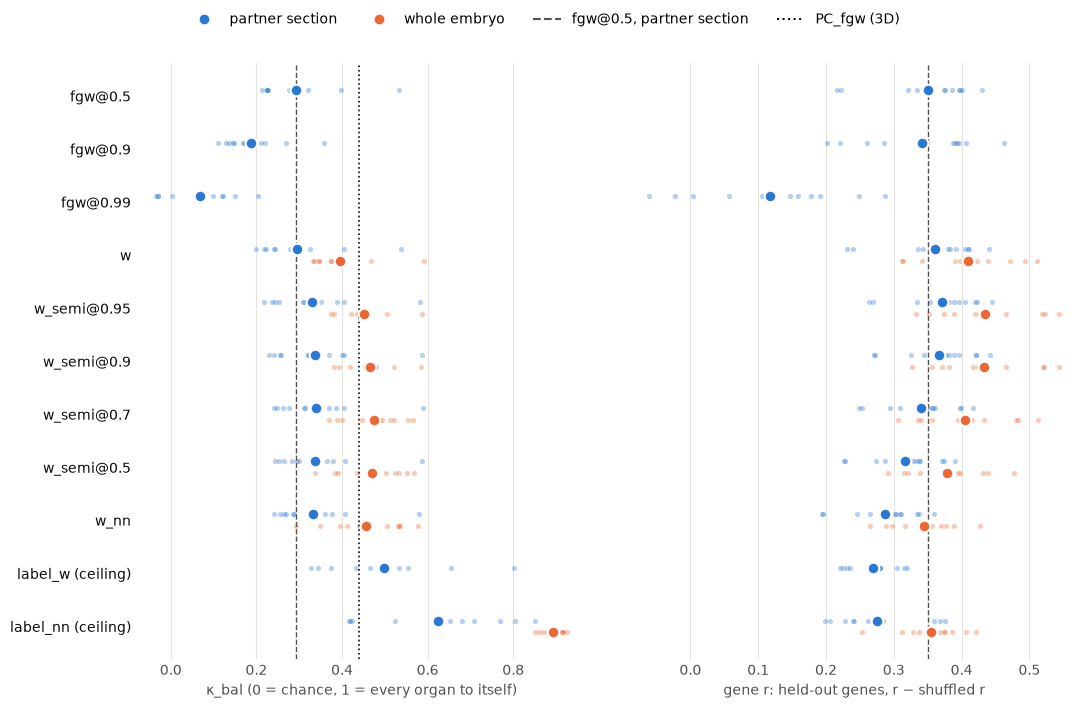

In [15]:
SECTION, EMBRYO = "#2a78d6", "#eb6834"            # categorical slots 1 and 2 (validated pair)
kind_color = {"sec2part": SECTION, "sec2emb": EMBRYO}
ceiling = lambda r: f"{r} (ceiling)" if "f-lab" in r else r
fig, axes = plt.subplots(1, 2, figsize=(11, 0.5 * len(FU_ORDER) + 1.6), sharey=True)
for ax, col, xlabel in ((axes[0], "kappa_bal", "κ_bal (0 = chance, 1 = every organ to itself)"),
                        (axes[1], "gene_r", "gene r: held-out genes, r − shuffled r")):
    for k, (kind, color) in enumerate(kind_color.items()):
        off = (k - 0.5) * 0.22
        for i, run in enumerate(FU_ORDER):
            v = fu[(fu.run == run) & (fu.kind == kind)][col].to_numpy()
            if len(v):
                ax.scatter(v, np.full(len(v), i + off), s=14, color=color, alpha=0.35, linewidths=0)
                ax.scatter([np.nanmean(v)], [i + off], s=70, color=color, edgecolors="white", linewidths=1.5,
                           zorder=3)
    ax.axvline(part.loc["s-euc_f-euc_bal", col], color=MUTED, ls="--", lw=1)
    ax.set_xlabel(xlabel, color=MUTED)
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ax.spines.values():
        s.set_visible(False)
if pc3d is not None:
    axes[0].axvline(pc_mean, color=INK, ls=":", lw=1.2)
axes[0].set_yticks(range(len(FU_ORDER)), [ceiling(r) for r in FU_ORDER], color=INK)
axes[0].invert_yaxis()
handles = [Line2D([], [], marker="o", ls="", color=c, label={"sec2part": "sec2part (partner section)", "sec2emb": "sec2emb (whole embryo)"}[k])
           for k, c in kind_color.items()]
handles.append(Line2D([], [], ls="--", color=MUTED, label="sec2part_s-euc_f-euc_bal"))
if pc3d is not None:
    handles.append(Line2D([], [], ls=":", color=INK, label=f"{PC3D} (3D)"))
fig.legend(handles=handles, loc="upper center", ncol=len(handles), frameon=False)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.45 / fig.get_figheight()), w_pad=3)
plt.show()

**How to read the follow-ups**
- **`s-eucα_f-euc_bal` against `s-none_f-euc_bal`:** if κ_bal or gene r rise with α, space helps once it has weight. The objective terms show whether `s-euc_f-euc_bal` differs from `s-none_f-euc_bal` at all.
- **The τ_b sweep:** what the balanced target marginal costs. If κ_bal keeps rising down to `s-none_f-euc_nn`, the marginal constraint hurts; a peak in between means some balance helps (it keeps many query spots from collapsing onto a few target spots; see target_used).
- **Ceiling:** `s-none_f-lab_nn` is what the partner section allows at all (organs it lacks cannot be matched). Against `sec2part_s-none_f-lab_bal` (`label_alignment.ipynb`): what the balanced marginals cost even with perfect costs.
- **Whole embryo against partner section:** the gain from choosing among all depths. dL shows whether the features pick target spots at a similar depth. Against `pts2pts_s-euc_f-euc_ub`: what the 3D stack adds beyond that.

## Solve and score

For every pair of sections, run and τ, P is scored right away for each query section it serves:
- **κ_bal** (`task.score`, exactly as in the benchmark; K counts the organs of the whole target embryo);
- **gene r**, the held-out genes through P (`crossspecies.coexpression`), mean r minus the shuffled mean r;
- **matched**, the mass P transports (1 when balanced);
- **flip**, whether the rigid map fitted to P (`stack3d.procrustes`) is a reflection when that of balanced `s-euc_f-euc` is not, or the reverse.

Only the couplings that figure 2 draws are kept (all of them would take tens of GB).

In [ ]:
SHOW_RUNS = ["s-euc_f-euc", "s-euc_f-none", "s-none_f-euc"]

kept, solves, rows = {}, [], []
for h, m in pairs:
    t0 = time.perf_counter()
    for run in RUNS:
        for tau in TAUS:
            Phm, info = solve(run, H[h], Mo[m], tau)
            if not np.isfinite(Phm).all():
                raise FloatingPointError(f"{run} tau {tau}: non-finite coupling for {h} x {m}")
            solves.append(dict(run=run, tau=tau, human=h, mouse=m, mass=Phm.sum(), seconds=info.get("seconds"),
                               converged=info.get("converged")))
            if run in SHOW_RUNS and tau == 1.0:
                kept[run, h, m] = Phm.astype(np.float32)
            for d, qn, tn in serves[h, m]:
                q, t, Pq = (H[qn], Mo[tn], Phm) if d == "b_stack" else (Mo[qn], H[tn], Phm.T)
                r, r0 = cs.coexpression(Pq, q.Y, t.Y, seed=SEED)
                R, _ = s3.procrustes([(task.xy(q), task.xy(t), Pq)])
                rows.append(dict(run=run, tau=tau, direction=d, query=qn, target=tn,
                                 kappa_bal=task.score(d, q, t.name, t.comp, Pq, keep=False)["kappa_bal"],
                                 gene_r=np.nanmean(r) - np.nanmean(r0), matched=Pq.sum(),
                                 reflection=np.linalg.det(R) < 0))
    print(f"{h} ({H[h].n}) x {m} ({Mo[m].n}): {len(RUNS) * len(TAUS)} solves, {time.perf_counter() - t0:.0f} s")

solves = pd.DataFrame(solves)
print("\nmean transported mass and seconds per solve:")
print(solves.groupby(["run", "tau"], sort=False)[["mass", "seconds"]].mean().round(3).unstack("tau").to_string())
if not solves.converged.astype(bool).all():
    print("\nnot converged:", solves.loc[~solves.converged.astype(bool), ["run", "tau", "human", "mouse"]]
          .to_string(index=False))

In [ ]:
scores = pd.DataFrame(rows)
ref = scores[(scores.run == "s-euc_f-euc") & (scores.tau == 1.0)].set_index(["direction", "query"]).reflection
scores["flip"] = scores.reflection.to_numpy() != ref.loc[list(zip(scores.direction, scores["query"]))].to_numpy()

summary = (scores.groupby(["run", "tau"], sort=False)
           .agg(kappa_bal=("kappa_bal", "mean"), gene_r=("gene_r", "mean"), matched=("matched", "mean"),
                flips=("flip", "sum"), n=("query", "size")))
print(summary.round(3).to_string())

# the reference against the benchmark: balanced s-euc_f-euc should reproduce PIPELINE's candidate rows of the
# same pairs
bench = store.result_dir(root, cfg, PIPELINE, pair.id, SEED) / "scores.csv"
if bench.exists():
    b = pd.read_csv(bench).query("role == 'candidate'").set_index(["direction", "query", "target"]).kappa_bal
    ours = scores[(scores.run == "s-euc_f-euc") & (scores.tau == 1.0)].set_index(["direction", "query", "target"]).kappa_bal
    both = pd.concat([ours.rename("here"), b.rename(PIPELINE)], axis=1, join="inner")
    print(f"\ns-euc_f-euc (balanced) vs {PIPELINE} on {len(both)} shared rows: "
          f"max |difference| in kappa_bal {np.abs(both.here - both[PIPELINE]).max():.4f}")
else:
    print(f"\nno {PIPELINE} results at {bench}; the reference check is skipped")

## Figure 1: every run against the reference

Large markers show the mean over the query sections of both directions; small dots show single sections. The dashed line marks balanced `s-euc_f-euc`. Better is to the right in both panels.

In [ ]:
BAL, UNB = "#2a78d6", "#eb6834"                   # categorical slots 1 and 2 (validated pair)
tau_color = {TAUS[0]: BAL, **({TAUS[1]: UNB} if len(TAUS) > 1 else {})}
tau_name = lambda tau: "bal (τ = 1)" if tau == 1 else f"ub (τ = {tau:g})"
order = list(RUNS)


def style(ax, xlabel):
    ax.set_xlabel(xlabel, color=MUTED)
    ax.tick_params(colors=MUTED, length=0)
    ax.grid(axis="x", color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for s in ax.spines.values():
        s.set_visible(False)


fig, axes = plt.subplots(1, 2, figsize=(11, 0.55 * len(order) + 1.6), sharey=True)
for ax, col, xlabel in ((axes[0], "kappa_bal", "κ_bal (0 = chance, 1 = every organ to itself)"),
                        (axes[1], "gene_r", "gene r: held-out genes, r − shuffled r")):
    for k, tau in enumerate(TAUS):
        off = (k - (len(TAUS) - 1) / 2) * 0.22
        for i, run in enumerate(order):
            v = scores[(scores.run == run) & (scores.tau == tau)][col].to_numpy()
            ax.scatter(v, np.full(len(v), i + off), s=14, color=tau_color[tau], alpha=0.35, linewidths=0)
            ax.scatter([np.nanmean(v)], [i + off], s=70, color=tau_color[tau], edgecolors="white", linewidths=1.5,
                       zorder=3)
    ax.axvline(summary.loc[("s-euc_f-euc", 1.0), col], color=MUTED, ls="--", lw=1)
    style(ax, xlabel)
axes[0].set_yticks(range(len(order)), order, color=INK)
axes[0].invert_yaxis()
fig.legend(handles=[Line2D([], [], marker="o", ls="", color=tau_color[t], label=tau_name(t)) for t in TAUS]
           + [Line2D([], [], ls="--", color=MUTED, label="s-euc_f-euc, bal")],
           loc="upper center", ncol=len(TAUS) + 1, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.45 / fig.get_figheight()))
plt.show()

## Figure 2: the organs each run transfers

One row per human section, all balanced. From left to right:
1. the annotation of its mouse partner, where the labels come from;
2. the annotation of the human section;
3. the organs transferred along each coupling (arg-max, `metrics.hard_prediction`).

The eight most frequent organs of the pair have their own colours; the rest are "Other".

In [ ]:
rows3 = [(q, t) for d, q, t in queries if d == "b_stack" and (SHOW_SECTIONS is None or q in SHOW_SECTIONS)]
pal = organ_palette([np.concatenate([s.label for s in H.values()]), np.concatenate([s.label for s in Mo.values()])])
colors = lambda labels: [pal.get(l, OTHER) for l in np.asarray(labels, dtype=str)]
kb = scores[(scores.direction == "b_stack") & (scores.tau == 1.0)].set_index(["run", "query"]).kappa_bal

ncol = 2 + len(SHOW_RUNS)
fig, axes = plt.subplots(len(rows3), ncol, figsize=(2.6 * ncol, 2.6 * len(rows3)), squeeze=False)
for (qn, tn), ax in zip(rows3, axes):
    q, t = H[qn], Mo[tn]
    panels = [(t.xy, t.label, f"{tn} (mouse)\nL {t.L:.2f}: annotated"),
              (q.xy, q.label, f"{qn} (human)\nL {q.L:.2f}: annotated")]
    for run in SHOW_RUNS:
        pred = np.asarray(metrics.ORGANS)[metrics.hard_prediction(kept[run, qn, tn], t.comp)]
        panels.append((q.xy, pred, f"{run}\nκ_bal {kb[run, qn]:.2f}"))
    for a, (xy, lab, title) in zip(ax, panels):
        a.scatter(*np.asarray(xy).T, s=float(np.clip(9000 / len(xy), 1, 12)), c=colors(lab), linewidths=0)
        a.set_aspect("equal"); a.axis("off"); a.set_title(title, fontsize=9, color=INK)
handles = [Line2D([], [], marker="o", ls="", color=c, label=o) for o, c in pal.items()]
handles.append(Line2D([], [], marker="o", ls="", color=OTHER, label="Other"))
fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.8 / fig.get_figheight()))
plt.show()

## Per-section table

In [ ]:
wide = scores.pivot_table(index=["direction", "query", "target"], columns=["run", "tau"],
                          values=["kappa_bal", "gene_r"]).round(3)
print(wide.to_string())

## How to read the results

- **`s-euc_f-none` against `s-euc_f-euc`:** what the features add to space. If `s-euc_f-none` is near `s-euc_f-euc`, the features contribute little. If `s-euc_f-none` has many `flips`, the mirror ambiguity is part of what hurts space alone.
- **`s-none_f-euc` against `s-euc_f-euc`:** what space adds to the features. If `s-none_f-euc` is close or better, the GW term mostly constrains (or fights) the match.
- **Balanced against unbalanced:** how much of the damage comes from tissue without a counterpart (depth mismatch). Read the gaps together with `matched`.